# 06 · Fiber coupling: Monte Carlo vs theory

How much received power couples into a single-mode fiber depends on the aperture diameter D relative to r₀:
above D/r₀ ≈ 1 the wavefront breaks into several coherence cells and the efficiency η drops quickly. This
notebook draws many *independent* channel realizations, measures η for three apertures, and compares the
ensemble mean with the von Kármán prediction, with and without removing tip/tilt (README §8.6).

`reseed` starts a new independent realization (fresh screens and random streams) without rebuilding the
graphs or the extrusion operators, so only the first realization pays for the build.

> **About the outputs.** The results stored in this notebook were produced on an NVIDIA GeForce RTX 4080
> (16 GiB) under Windows. Timings, and the run mode the memory guard picks, depend on the GPU; the statistics
> do not. Open the notebook in Jupyter or VS Code with the OPAL environment as the kernel and run the cells in
> order. The first cell moves to the repository root, so every path below is relative to it.

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")      # hide TensorFlow's C++ start-up messages
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs").is_dir())
os.chdir(ROOT)                                           # paths below are relative to the repository root

import time
import numpy as np
import matplotlib.pyplot as plt
import opal

%matplotlib inline
plt.rcParams.update({"figure.dpi": 80, "image.origin": "lower"})
print("OPAL", opal.__version__)

OPAL 1.1.0


In [2]:
import tensorflow as tf
from opal.analysis import compute_fiber_coupling, coupling_efficiency_theoretical_vk, remove_tilt_com

REALIZATIONS = 120          # eta is heavy-tailed at large D/r0: its mean needs many samples
APERTURES = (0.2, 0.3, 0.5)  # m, must stay below 0.47 * N * dx

sim = opal.GpuSimulator(opal.load_config("configs/quickstart_256.json"))
dx, r0, L0 = sim.px_delta, sim.total_r0, 25.0
ones = tf.ones([1, sim.num_layers], tf.float32)

t0 = time.time()
fields = []
for k in range(REALIZATIONS):
    sim.reseed(10_000 + k)
    fields.append(sim.simulate_steps_no_save(tf.constant(1), ones).numpy())
fields = np.stack(fields)
print(f"{REALIZATIONS} independent realizations in {time.time() - t0:.1f} s, r0 = {r0} m, L0 = {L0} m")

120 independent realizations in 120.8 s, r0 = 0.1 m, L0 = 25.0 m


In [3]:
results = {}
print(" D (m)  D/r0   eta (MC)          eta (theory)   eta, tip/tilt removed")
for D in APERTURES:
    eta = compute_fiber_coupling(fields, dx, aperture_diameter=D)["eta"]
    corrected, _ = remove_tilt_com(fields, dx, aperture_diameter=D)
    eta_tt = compute_fiber_coupling(corrected, dx, aperture_diameter=D)["eta"]
    theory = coupling_efficiency_theoretical_vk(D, r0, L0)
    results[D] = (eta, eta_tt, theory)
    print(f" {D:4.2f}  {D / r0:5.1f}  {eta.mean():.3f} +- {eta.std() / np.sqrt(REALIZATIONS):.3f}   "
          f"{theory:.3f}          {eta_tt.mean():.3f}")

 D (m)  D/r0   eta (MC)          eta (theory)   eta, tip/tilt removed


 0.20    2.0  0.220 +- 0.016   0.211          0.532


 0.30    3.0  0.108 +- 0.010   0.113          0.365


 0.50    5.0  0.040 +- 0.004   0.045          0.143


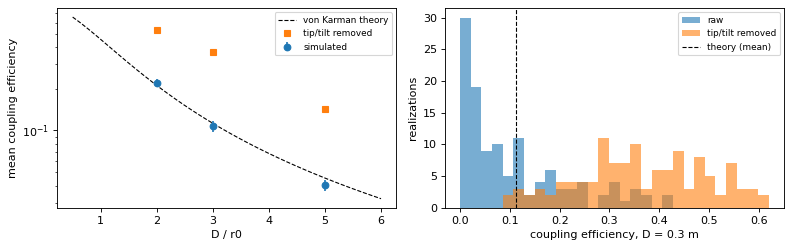

In [4]:
D_grid = np.linspace(0.05, 0.6, 40)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
ax = axes[0]
ax.plot(D_grid / r0, [coupling_efficiency_theoretical_vk(D, r0, L0) for D in D_grid], "k--", lw=1,
        label="von Karman theory")
ax.errorbar([D / r0 for D in APERTURES], [results[D][0].mean() for D in APERTURES],
            yerr=[results[D][0].std() / np.sqrt(REALIZATIONS) for D in APERTURES], fmt="o", label="simulated")
ax.plot([D / r0 for D in APERTURES], [results[D][1].mean() for D in APERTURES], "s", label="tip/tilt removed")
ax.set(xlabel="D / r0", ylabel="mean coupling efficiency", yscale="log")
ax.legend(fontsize=8)

eta, eta_tt, theory = results[0.3]
bins = np.linspace(0, max(eta.max(), eta_tt.max()), 30)
axes[1].hist(eta, bins, alpha=0.6, label="raw")
axes[1].hist(eta_tt, bins, alpha=0.6, label="tip/tilt removed")
axes[1].axvline(theory, color="k", ls="--", lw=1, label="theory (mean)")
axes[1].set(xlabel="coupling efficiency, D = 0.3 m", ylabel="realizations")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

Removing tip/tilt (the overall wavefront slope, what a fast steering mirror corrects) recovers a large part of
the lost coupling at moderate D/r₀; the remainder is higher-order aberration that needs adaptive optics.

For a saved run, `opal analyze fiber RUN --frames all` gives the per-frame η of one time series (notebook 01);
reseeded realizations like the ones above are the right input for ensemble statistics.